## Step 3: Define the groups

This notebook decides which patients go in which group, so the next notebook can ask which genes are different between them.

I split patients by **IDH status**, not by tumor grade. The Ceccarelli paper found that IDH status tells you more about how a patient will do than grade does, and my own data agrees. IDH wild-type tumors are mostly aggressive and IDH mutant tumors are mostly slower.

However, more than half of the IDH wild-type tumors are glioblastomas, and almost all of the IDH mutant tumors are lower grade gliomas. So if I only compared those two groups, then I couldn't tell whether a gene is different because of the IDH mutation or just because one set is higher grade. To get around that, I made three comparisons.

- **Comparison A.** IDH mutant versus IDH wild-type, using everyone.
- **Comparison B.** IDH mutant versus IDH wild-type, using only lower grade gliomas. This removes the glioblastoma effect. Genes that show up in both A and B are the most trustworthy.
- **Comparison C.** Lower grade versus glioblastoma, using only IDH wild-type tumors. This shows what changes as an IDH wild-type tumor becomes more aggressive, which is the progression question from the paper.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 20

purple = "#5B3A8C"
dark_blue = "#1F3A6B"
light_purple = "#A794C9"

Path("csv").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

data_dir = Path.home() / "Desktop" / "PROJECT_4_PORT"
print("Done")

Done


In [2]:
#Load what step 1 saved
patient_table = pd.read_csv("csv/patient_table.csv")
log_expr = pd.read_csv(data_dir / "processed" / "expression_log2.csv.gz", index_col=0)

# make sure the gene activity columns are in the same order as the patient table
log_expr = log_expr[patient_table["PATIENT_ID"]]

print("Patients:", len(patient_table))
print("Genes:", log_expr.shape[0])

Patients: 667
Genes: 20511


### Groups
`IDH_STATUS` says whether a tumor carries the IDH mutation. A few patients have no IDH result, and they are left out of every comparison.

In [3]:
patient_table["idh_group"] = patient_table["IDH_STATUS"].map({"Mutant": "IDH mutant", "WT": "IDH wild-type"})
patient_table["tumor_type"] = patient_table["cohort"].map({"LGG": "Lower grade", "GBM": "Glioblastoma"})

# comparison A: everyone with an IDH result
patient_table["compare_A"] = patient_table["idh_group"]

# comparison B: lower grade tumors only
patient_table["compare_B"] = patient_table["idh_group"].where(patient_table["tumor_type"] == "Lower grade")

# comparison C: IDH wild-type tumors only
patient_table["compare_C"] = patient_table["tumor_type"].where(patient_table["idh_group"] == "IDH wild-type")

print("Patients with no IDH result:", int(patient_table["idh_group"].isna().sum()))

Patients with no IDH result: 7


### How big is each group?
A comparison needs enough patients on both sides. As a rule of thumb, we want at least 20 in each group.

In [4]:
for name, column in [("A: IDH mutant versus IDH wild-type, everyone", "compare_A"),
                     ("B: IDH mutant versus IDH wild-type, lower grade only", "compare_B"),
                     ("C: Lower grade versus glioblastoma, IDH wild-type only", "compare_C")]:
    print("Comparison " + name)
    print(patient_table[column].value_counts().to_string())
    print()

Comparison A: IDH mutant versus IDH wild-type, everyone
compare_A
IDH mutant       426
IDH wild-type    234

Comparison B: IDH mutant versus IDH wild-type, lower grade only
compare_B
IDH mutant       417
IDH wild-type     94

Comparison C: Lower grade versus glioblastoma, IDH wild-type only
compare_C
Glioblastoma    140
Lower grade      94



### Are the groups different in other ways?
Age matters here. If one group is much older, some of what we find could be about age and not the tumor. The next table shows the median age and the share of men in each group, so we know what to keep in mind.

In [5]:
by_group = (patient_table.dropna(subset=["idh_group"])
            .groupby(["idh_group", "tumor_type"])
            .agg(patients=("PATIENT_ID", "count"),
                 median_age=("AGE", "median"),
                 share_male=("SEX", lambda s: round(float((s == "Male").mean()), 2)),
                 share_deceased=("event", lambda s: round(float(s.mean()), 2))))
print(by_group.to_string())

                            patients  median_age  share_male  share_deceased
idh_group     tumor_type                                                    
IDH mutant    Glioblastoma         9        38.0        0.78            0.56
              Lower grade        417        39.0        0.55            0.18
IDH wild-type Glioblastoma       140        62.0        0.64            0.81
              Lower grade         94        57.0        0.55            0.53


### Do the groups look different in the gene activity?
Before testing individual genes, this gives a bird's eye view. Each dot is a patient. We take the 2,000 genes that vary the most between patients and squash them down to two numbers per patient, so patients with similar gene activity land near each other. This is called a PCA plot. If the IDH groups really are different, they should land in different places. Circles are lower grade gliomas and triangles are glioblastomas.

In [6]:
# pick the 2,000 genes that vary the most, and put each gene on the same scale
spread = log_expr.var(axis=1).sort_values(ascending=False)
top = log_expr.loc[spread.index[:2000]]
scaled = top.sub(top.mean(axis=1), axis=0).div(top.std(axis=1), axis=0)

# squash to two numbers per patient
u, s, vt = np.linalg.svd(scaled.T.to_numpy(), full_matrices=False)
coords = u[:, :2] * s[:2]
explained = (s ** 2) / (s ** 2).sum()

patient_table["pc1"] = coords[:, 0]
patient_table["pc2"] = coords[:, 1]

print("Share of variation in the first axis:", round(float(explained[0]) * 100, 1), "%")
print("Share of variation in the second axis:", round(float(explained[1]) * 100, 1), "%")

Share of variation in the first axis: 29.9 %
Share of variation in the second axis: 12.9 %


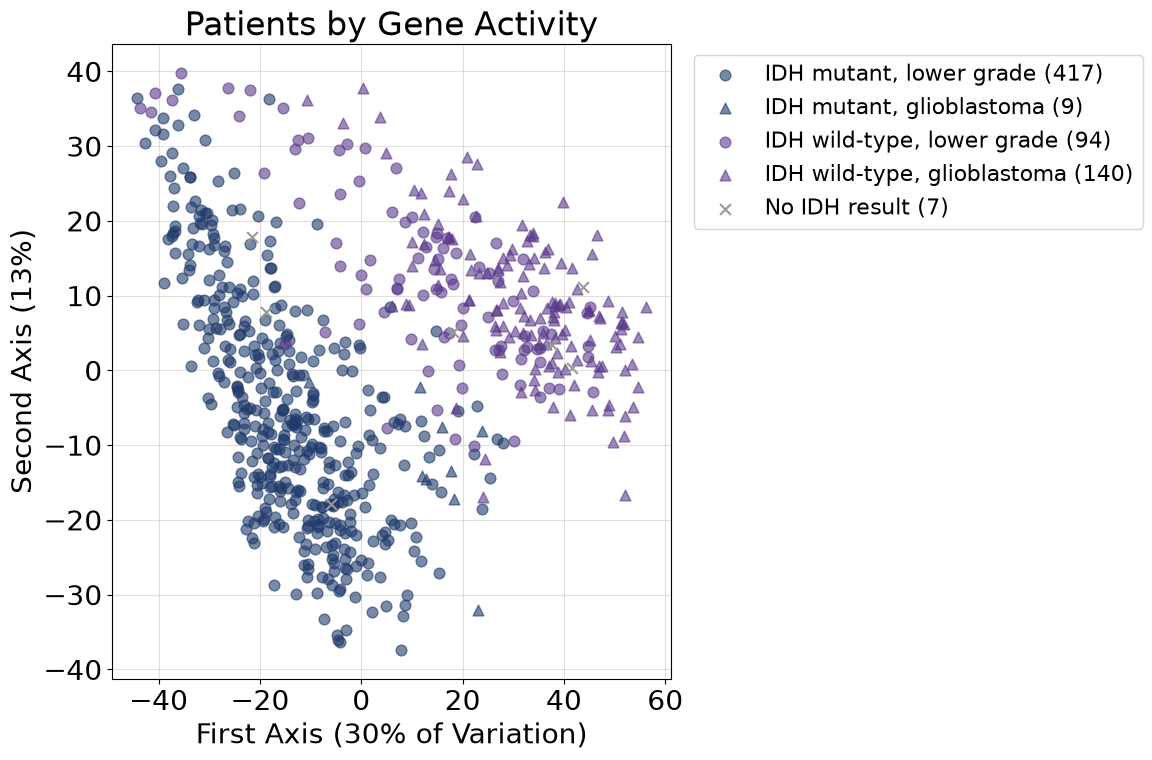

In [8]:
fig, ax = plt.subplots(figsize=(12, 8))

styles = [("IDH mutant", "Lower grade", dark_blue, "o"),
          ("IDH mutant", "Glioblastoma", dark_blue, "^"),
          ("IDH wild-type", "Lower grade", purple, "o"),
          ("IDH wild-type", "Glioblastoma", purple, "^")]

for idh, tumor, color, marker in styles:
    rows = patient_table[(patient_table["idh_group"] == idh) & (patient_table["tumor_type"] == tumor)]
    ax.scatter(rows["pc1"], rows["pc2"], c=color, marker=marker, s=60, alpha=0.6,
               label=idh + ", " + tumor.lower() + " (" + str(len(rows)) + ")")

unknown = patient_table[patient_table["idh_group"].isna()]
ax.scatter(unknown["pc1"], unknown["pc2"], c="#999999", marker="x", s=60, label="No IDH result (" + str(len(unknown)) + ")")

ax.set_title("Patients by Gene Activity")
ax.set_xlabel("First Axis (" + str(round(float(explained[0]) * 100)) + "% of Variation)")
ax.set_ylabel("Second Axis (" + str(round(float(explained[1]) * 100)) + "%)")
ax.grid(True, alpha=0.4)
ax.set_axisbelow(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=16)
plt.tight_layout()
plt.savefig("figures/p4-pca-by-group.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
patient_table.to_csv("csv/patient_groups.csv", index=False)
print("Saved csv/patient_groups.csv with", len(patient_table), "patients")

Saved csv/patient_groups.csv with 667 patients
